# 04 — Faire tenir 7 milliards de paramètres sur un GPU : mémoire et quantification 4 bits

**Chapitre 3** · durée conseillée : 25 min · CPU uniquement (< 1 min de calcul) · [![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/chapitre_3/04_memoire_quantification.ipynb)

![Parcours du chapitre 3](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_3/figures/00_parcours.png)

Le GPU gratuit de Google Colab (NVIDIA T4) a **15 Go** de mémoire. Mistral 7B en BF16 pèse déjà **14,5 Go** sans rien entraîner. Ce notebook fait les comptes, puis construit à la main la **quantification NF4** qui permet le QLoRA du notebook 05.

**À la fin de ce notebook, vous saurez :**
1. décomposer la mémoire d'un entraînement : poids, gradients, états de l'optimiseur, activations ;
2. estimer la mémoire d'un full fine-tuning, d'un LoRA et d'un QLoRA de Mistral 7B ;
3. quantifier une matrice en 4 bits **par blocs**, et expliquer pourquoi NF4 est meilleur que des niveaux réguliers ;
4. expliquer QLoRA, l'**accumulation de gradient** et le **gradient checkpointing**.

In [1]:
# Préparation. Sur Colab : on récupère le dépôt du cours (données + modules partagés).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("finetune.py"):
    !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/chapitre_3
sys.path.insert(0, "../chapitre_2")   # minigpt.py du chapitre 2

import math, random, warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # avertissement tqdm sans importance
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import finetune as ft   # fichier finetune.py, à côté de ce notebook
torch.manual_seed(1337)
print("PyTorch", torch.__version__)
import minigpt
import numpy as np
from pathlib import Path

PyTorch 2.15.0+cu132


## 1. Où va la mémoire pendant un entraînement ?

| Type | Octets par nombre | Usage |
|---|---|---|
| FP32 | 4 | précision « classique » (chapitre 2) |
| BF16 / FP16 | 2 | poids et calculs des LLM modernes |
| INT8 | 1 | quantification 8 bits |
| NF4 | 0,5 | quantification 4 bits de QLoRA |

Pour **chaque paramètre entraînable**, un entraînement avec AdamW stocke :
- le **poids** lui-même ;
- son **gradient** (même taille) ;
- deux **états AdamW** (moyenne et variance des gradients, chapitre 2 notebook 02), en FP32 : 8 octets.

S'ajoutent les **activations** : les sorties intermédiaires de chaque couche, gardées pendant le forward pour calculer le backward. Elles dépendent du **batch** et de la **longueur des séquences**, pas du nombre de paramètres.

Pour Mistral 7B (7,25 milliards de paramètres), `ft.memoire_entrainement` fait le compte :

                     poids   grads   AdamW  activ.   TOTAL   (Go, batch 1 x 512 tokens)
Full FT (BF16)       13.50   13.50   54.00    0.32    81.3
LoRA (base BF16)     13.66    0.16    0.31    0.32    14.4
QLoRA (base NF4)      4.10    0.16    0.31    0.32     4.9


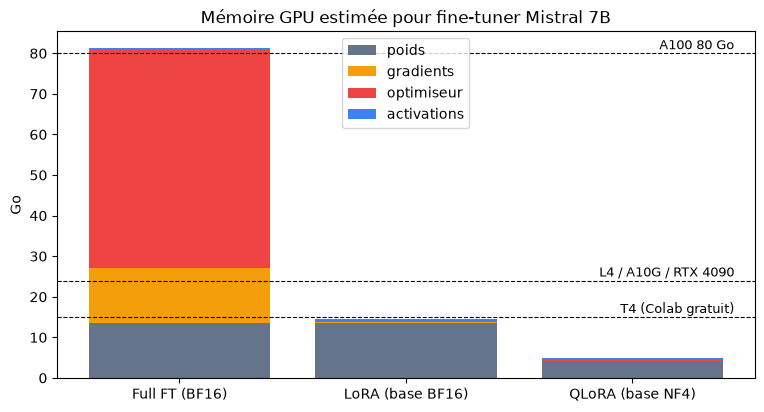

In [2]:
methodes = {"full": "Full FT (BF16)", "lora": "LoRA (base BF16)", "qlora": "QLoRA (base NF4)"}
estimations = {m: ft.memoire_entrainement(m, r=16, batch=1, seq=512) for m in methodes}

print(f"{'':18s} {'poids':>7s} {'grads':>7s} {'AdamW':>7s} {'activ.':>7s} {'TOTAL':>7s}   (Go, batch 1 x 512 tokens)")
for m, e in estimations.items():
    print(f"{methodes[m]:18s} " + " ".join(f"{v:7.2f}" for v in e.values()) + f" {sum(e.values()):7.1f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
bas = np.zeros(3)
for partie, couleur in zip(["poids", "gradients", "optimiseur", "activations"], ["#64748b", "#f59e0b", "#ef4444", "#3b82f6"]):
    valeurs = np.array([estimations[m][partie] for m in methodes])
    ax.bar(list(methodes.values()), valeurs, bottom=bas, label=partie, color=couleur)
    bas += valeurs
for gpu, go in [("T4 (Colab gratuit)", 15), ("L4 / A10G / RTX 4090", 24), ("A100 80 Go", 80)]:
    ax.axhline(go, ls="--", color="black", lw=0.8)
    ax.text(2.45, go + 1, gpu, ha="right", fontsize=9)
ax.set_ylabel("Go"); ax.set_title("Mémoire GPU estimée pour fine-tuner Mistral 7B"); ax.legend(loc="upper center")
plt.show()

**Lecture :**
- **Full fine-tuning** : ~81 Go, dont les deux tiers pour AdamW. Il faut un A100 80 Go, en réalité plusieurs GPU (les activations et le surcoût CUDA s'ajoutent).
- **LoRA** : gradients et AdamW **disparaissent** presque (42 M de paramètres entraînables au lieu de 7 250 M). Mais la base en BF16 occupe encore 13,5 Go : ça ne tient pas sur un T4.
- **QLoRA** : on stocke la base en **4 bits** → ~4 Go de poids. Total ≈ 5 Go : tient sur un T4.

Ces chiffres sont des **ordres de grandeur** : le contexte CUDA (~0,5–1 Go), la fragmentation de la mémoire et les tampons de déquantification ajoutent 1 à 3 Go. Au notebook 05, on mesure la mémoire réelle avec `torch.cuda.max_memory_allocated()`.

## 2. Les activations : longueur des séquences et gradient checkpointing

Les activations sont proportionnelles au nombre de tokens dans le batch (`batch × seq`). Sans précaution, il faut garder ~34·d octets par token **et par couche** (Korthikanti et al., 2022).

Le **gradient checkpointing** ne garde que l'**entrée** de chaque bloc pendant le forward ; pendant le backward, il **recalcule** le forward du bloc pour retrouver ses activations. Mémoire divisée par ~10, calcul ralenti d'environ 30 %.

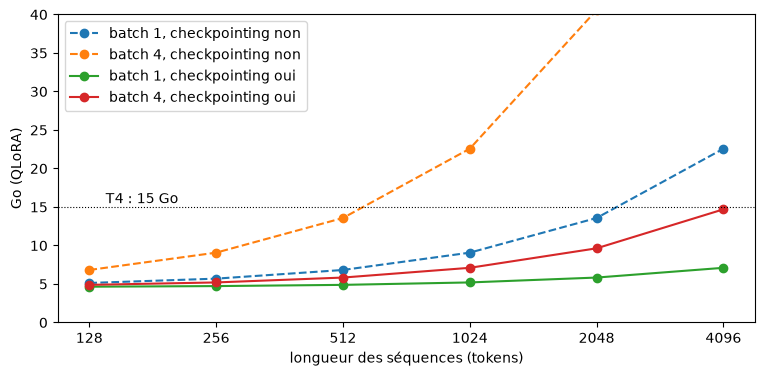

In [3]:
longueurs = [128, 256, 512, 1024, 2048, 4096]
fig, ax = plt.subplots(figsize=(9, 4))
for gc, style in [(False, "o--"), (True, "o-")]:
    for batch in [1, 4]:
        tot = [sum(ft.memoire_entrainement("qlora", batch=batch, seq=s, gradient_checkpointing=gc).values()) for s in longueurs]
        ax.plot(longueurs, tot, style, label=f"batch {batch}, checkpointing {'oui' if gc else 'non'}")
ax.axhline(15, color="black", lw=0.8, ls=":"); ax.text(140, 15.5, "T4 : 15 Go")
ax.set_xscale("log", base=2); ax.set_xticks(longueurs, longueurs)
ax.set_xlabel("longueur des séquences (tokens)"); ax.set_ylabel("Go (QLoRA)"); ax.set_ylim(0, 40); ax.legend()
plt.show()

C'est pourquoi on a choisi `max_length = 512` à partir des données (notebook 02) et non 32 768 : sans checkpointing, quelques milliers de tokens suffisent à saturer le GPU.

## 3. Combien de paramètres LoRA ?

`target_modules` et `r` fixent le nombre de paramètres entraînables (formule du notebook 03 : `r·(d + k)` par matrice, × 32 couches).

In [4]:
attention = ["q_proj", "k_proj", "v_proj", "o_proj"]
toutes = attention + ["gate_proj", "up_proj", "down_proj"]
n_total = sum(ft.parametres_mistral().values())
print(f"{'cibles':22s} " + " ".join(f"{'r=' + str(r):>16s}" for r in [8, 16, 32, 64]))
for nom, cibles in [("q, v (LoRA original)", ["q_proj", "v_proj"]), ("attention (q,k,v,o)", attention), ("toutes les linéaires", toutes)]:
    print(f"{nom:22s} " + " ".join(f"{ft.parametres_lora(r, cibles) / 1e6:7.1f} M ({ft.parametres_lora(r, cibles) / n_total:5.2%})" for r in [8, 16, 32, 64]))

cibles                              r=8             r=16             r=32             r=64
q, v (LoRA original)       3.4 M (0.05%)     6.8 M (0.09%)    13.6 M (0.19%)    27.3 M (0.38%)
attention (q,k,v,o)        6.8 M (0.09%)    13.6 M (0.19%)    27.3 M (0.38%)    54.5 M (0.75%)
toutes les linéaires      21.0 M (0.29%)    41.9 M (0.58%)    83.9 M (1.16%)   167.8 M (2.31%)


Au notebook 05 : **r = 16 sur toutes les linéaires**, soit 42 M de paramètres (0,58 %). QLoRA (Dettmers et al., 2023) a montré qu'adapter **toutes** les couches linéaires compte plus que la valeur de `r`.

---
## 4. Quantifier : ranger des poids dans 16 cases

Quantifier en 4 bits, c'est remplacer chaque poids par l'un de **16 niveaux** (2⁴), et ne stocker que le **numéro** du niveau (4 bits). La recette :
1. découper la matrice en **blocs** de 64 poids ;
2. diviser chaque bloc par son **maximum absolu** (la *constante* du bloc, stockée à part) : les poids sont alors dans [-1, 1] ;
3. remplacer chaque poids par le **niveau le plus proche**.

Pour reconstruire (déquantifier) : `poids ≈ niveau[code] × constante`.

### Pourquoi des blocs ? Les valeurs aberrantes

In [5]:
torch.manual_seed(0)
w = torch.randn(4096) * 0.02          # des poids typiques : petits, autour de 0
w[100] = 1.0                          # une seule valeur aberrante (fréquent dans les LLM)

for taille_bloc in [4096, 64]:
    codes, _, w_q = ft.quantifier_par_blocs(w, ft.INT4, taille_bloc)
    erreur = (w - w_q).abs().mean().item()
    niveaux_utilises = len(set(codes.flatten().tolist()))
    print(f"bloc de {taille_bloc:4d} poids : erreur moyenne {erreur:.5f} | niveaux utilisés : {niveaux_utilises} / 16")

bloc de 4096 poids : erreur moyenne 0.05095 | niveaux utilisés : 3 / 16
bloc de   64 poids : erreur moyenne 0.00252 | niveaux utilisés : 16 / 16


Avec **une seule constante** pour toute la matrice, la valeur aberrante (1,0) fixe l'échelle : les 16 niveaux sont espacés de 0,13 et **tous** les poids ordinaires (de l'ordre de 0,02) tombent dans les deux cases qui encadrent zéro : 4 bits gaspillés pour ne garder qu'un signe. L'erreur est 20 fois plus grande. Avec des **blocs de 64**, seul le bloc de la valeur aberrante est abîmé.

### Pourquoi NF4 ? Les poids suivent une loi normale

Avec 16 niveaux **régulièrement espacés** (`INT4`), on gaspille des cases : les poids d'un réseau sont concentrés près de 0, les cases extrêmes sont presque vides. **NF4** (*NormalFloat 4 bits*) place les 16 niveaux aux **quantiles** d'une loi normale : chaque case reçoit à peu près **autant de poids**.

quantiles normalisés : ['-1.00', '-0.70', '-0.54', '-0.41', '-0.31', '-0.21', '-0.13', '-0.04', '+0.04', '+0.13', '+0.21', '+0.31', '+0.41', '+0.54', '+0.70', '+1.00']
NF4 (bitsandbytes)   : ['-1.00', '-0.70', '-0.53', '-0.39', '-0.28', '-0.18', '-0.09', '+0.00', '+0.08', '+0.16', '+0.25', '+0.34', '+0.44', '+0.56', '+0.72', '+1.00']


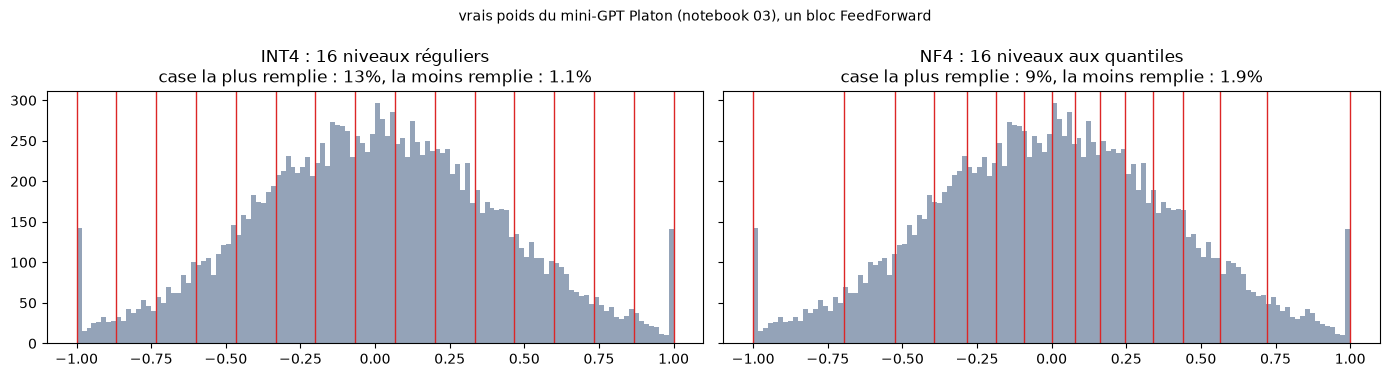

In [6]:
from torch.distributions import Normal
# Reconstruction approximative de NF4 : quantiles de la loi normale, renormalisés dans [-1, 1]
# (la version exacte de QLoRA est asymétrique pour avoir un zéro exact)
q = Normal(0, 1).icdf(torch.linspace(0.03, 0.97, 16))
print("quantiles normalisés :", [f"{v:+.2f}" for v in (q / q.abs().max()).tolist()])
print("NF4 (bitsandbytes)   :", [f"{v:+.2f}" for v in ft.NF4.tolist()])

ckpt = Path("checkpoints/minigpt_platon.pt")
if ckpt.exists():
    poids = torch.load(ckpt)["state_dict"]["blocks.1.ffwd.net.0.weight"].flatten()
    source = "vrais poids du mini-GPT Platon (notebook 03), un bloc FeedForward"
else:
    poids = torch.randn(16384) * 0.05
    source = "poids gaussiens (lancez le notebook 03 pour utiliser de vrais poids)"
blocs = poids[: len(poids) // 64 * 64].reshape(-1, 64)
normalises = (blocs / blocs.abs().amax(1, keepdim=True)).flatten()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, (nom, niveaux) in zip(axes, [("INT4 : 16 niveaux réguliers", ft.INT4), ("NF4 : 16 niveaux aux quantiles", ft.NF4)]):
    ax.hist(normalises, bins=120, color="#94a3b8")
    for v in niveaux:
        ax.axvline(v, color="#dc2626", lw=1)
    codes = (normalises.unsqueeze(-1) - niveaux).abs().argmin(-1)
    remplissage = torch.bincount(codes, minlength=16).float() / len(codes)
    ax.set_title(f"{nom}\ncase la plus remplie : {remplissage.max():.0%}, la moins remplie : {remplissage.min():.1%}")
fig.suptitle(source, fontsize=10)
plt.tight_layout(); plt.show()

In [7]:
torch.manual_seed(0)
W = torch.randn(1024, 1024) * 0.02
for nom, niveaux in [("INT4", ft.INT4), ("NF4", ft.NF4)]:
    _, _, W_q = ft.quantifier_par_blocs(W, niveaux, taille_bloc=64)
    print(f"{nom} : erreur quadratique moyenne {((W - W_q) ** 2).mean().item():.3e}")

INT4 : erreur quadratique moyenne 4.037e-06
NF4 : erreur quadratique moyenne 3.383e-06


NF4 réduit l'erreur de quantification à nombre de bits égal. Ce qui compte au final, c'est l'effet sur le **modèle** : quantifions toutes les couches linéaires du mini-GPT Platon (notebook 03) et mesurons sa loss.

In [8]:
if not ckpt.exists():
    print("Lancez d'abord le notebook 03 (il crée checkpoints/minigpt_platon.pt).")
else:
    sauve = torch.load(ckpt)
    chars = sauve["chars"]; stoi = {c: i for i, c in enumerate(chars)}
    texte = ft.charger_texte("platon")
    data = torch.tensor([stoi[c] for c in texte], dtype=torch.long)
    p_train, p_val = data[: int(0.9 * len(data))], data[int(0.9 * len(data)):]

    def loss_quantifiee(niveaux):
        m = minigpt.GPTLanguageModel(len(chars), 64, 64, 4, 4, dropout=0.0)
        m.load_state_dict(sauve["state_dict"])
        if niveaux is not None:
            with torch.no_grad():
                for nom, module in m.named_modules():
                    if isinstance(module, nn.Linear) and nom.startswith("blocks"):
                        module.weight.copy_(ft.quantifier_par_blocs(module.weight, niveaux, 64)[2])
        torch.manual_seed(0)
        return minigpt.estimate_loss(m, p_train, p_val, 32, 64, eval_iters=50)["val"]

    for nom, niveaux in [("FP32 (référence)", None), ("INT4 par blocs de 64", ft.INT4), ("NF4 par blocs de 64", ft.NF4)]:
        print(f"{nom:22s} val Platon = {loss_quantifiee(niveaux):.4f}")

FP32 (référence)       val Platon = 1.4497


INT4 par blocs de 64   val Platon = 1.4632


NF4 par blocs de 64    val Platon = 1.4620


Les poids passent de 32 à 4 bits (÷ 8) et la loss bouge à peine. Sur un modèle de 7 milliards de paramètres, très redondant, l'effet est encore plus faible : le papier QLoRA montre qu'un fine-tuning NF4 atteint la qualité d'un fine-tuning 16 bits.

### Le coût des constantes, et la double quantification

Chaque bloc de 64 poids a une constante FP32 (32 bits) : **0,5 bit** de plus par poids, soit 450 Mo sur Mistral 7B. QLoRA **quantifie aussi les constantes** (en 8 bits, par blocs de 256) :

In [9]:
n_quantifies = ft.parametres_mistral()["blocs (linéaires)"]
simple = 32 / 64
double = 8 / 64 + 32 / (64 * 256)
for nom, bits in [("NF4 simple", simple), ("NF4 + double quantification", double)]:
    print(f"{nom:28s} : {4 + bits:.3f} bits par poids -> {n_quantifies * (4 + bits) / 8 / 1024**3:.2f} Go pour les couches linéaires")

NF4 simple                   : 4.500 bits par poids -> 3.66 Go pour les couches linéaires
NF4 + double quantification  : 4.127 bits par poids -> 3.35 Go pour les couches linéaires


---
## 5. QLoRA : tout assembler

![QLoRA](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_3/figures/04_qlora.png)

- La base est **stockée** en NF4 et **gelée**.
- Pendant le calcul, chaque couche est **déquantifiée** à la volée en BF16 (ou FP16 sur un T4, qui ne gère pas le BF16), multipliée, puis jetée.
- Les adapters LoRA restent en haute précision et sont les **seuls** à recevoir des gradients.
- Le gradient **traverse** la base gelée (sinon les adapters des premières couches ne recevraient rien), mais aucun gradient n'est **stocké** pour ses poids.

Dans le notebook 05, tout cela tient en une configuration :

```python
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",              # les 16 niveaux de ft.NF4
    bnb_4bit_use_double_quant=True,         # constantes quantifiées en 8 bits
    bnb_4bit_compute_dtype=torch.bfloat16,  # déquantification vers BF16 (FP16 sur T4)
)
```

---
## 6. Deux astuces d'entraînement

### L'accumulation de gradient

On voudrait un batch de 16 exemples, mais seuls 4 tiennent en mémoire. Solution : faire 4 forward/backward de 4 exemples **sans** appeler `optimizer.step()`, en divisant chaque loss par 4. Les gradients **s'additionnent** dans `.grad` (c'est pour ça qu'on appelle `zero_grad()` au chapitre 2 !). Vérifions que c'est **exactement** le même gradient :

In [10]:
torch.manual_seed(0)
m = minigpt.GPTLanguageModel(vocab_size=50, block_size=16, n_embd=32, n_head=4, n_layer=2, dropout=0.0)
xb = torch.randint(0, 50, (16, 16)); yb = torch.randint(0, 50, (16, 16))

m.zero_grad()
_, loss = m(xb, yb); loss.backward()                       # un batch de 16
g_batch = m.lm_head.weight.grad.clone()

m.zero_grad()
for i in range(4):                                         # 4 micro-batchs de 4
    _, loss = m(xb[4 * i: 4 * i + 4], yb[4 * i: 4 * i + 4])
    (loss / 4).backward()                                  # les gradients s'ACCUMULENT
g_accumule = m.lm_head.weight.grad.clone()

print("gradients identiques :", torch.allclose(g_batch, g_accumule, atol=1e-6))

gradients identiques : True


Dans le notebook 05 : `per_device_train_batch_size=4, gradient_accumulation_steps=4` → **batch effectif** = 4 × 4 × (nombre de GPU = 1) = **16**.

> Avec des séquences de longueurs différentes, l'égalité n'est plus exacte (la moyenne se fait par token) ; les bibliothèques récentes corrigent ce point.

### Le gradient checkpointing

Vu au §2 : on échange du **calcul** contre de la **mémoire**. Dans `SFTConfig`, c'est `gradient_checkpointing=True` (activé par défaut dans TRL).

### Les optimiseurs « paginés »

Les pics de mémoire (une séquence exceptionnellement longue) peuvent faire planter un entraînement de plusieurs heures. `optim="paged_adamw_8bit"` stocke les états AdamW en 8 bits et peut les **déplacer temporairement en RAM** lors d'un pic, au lieu de lever `CUDA out of memory`.

---
## 7. Quel GPU sur Colab ?

| GPU | Mémoire | BF16 | Disponibilité | Mistral 7B QLoRA |
|---|---|---|---|---|
| **T4** | 15 Go | non (FP16) | gratuit (quotas variables) | ✔ batch 4 × 512 tokens |
| **L4** | 24 Go | oui | Colab Pro | ✔ plus rapide |
| **A100** | 40 Go | oui | Colab Pro | ✔ très confortable ; LoRA BF16 possible |

Le notebook 05 détecte le GPU et choisit FP16 ou BF16 automatiquement.

## À retenir

- Mémoire d'entraînement = **poids + gradients + états de l'optimiseur + activations**. AdamW coûte 8 octets par paramètre entraînable.
- **LoRA** supprime gradients et états AdamW de la base ; **QLoRA** stocke en plus la base en **NF4** (4 bits) : Mistral 7B passe de ~81 Go (full FT) à ~5 Go.
- Quantification **par blocs** (contre les valeurs aberrantes) avec des niveaux aux **quantiles de la loi normale** (NF4).
- **Accumulation de gradient** : un grand batch effectif avec peu de mémoire, résultat identique.
- **Gradient checkpointing** : recalculer au lieu de stocker les activations.

**Questions de vérification**
1. Pourquoi les états d'AdamW pèsent-ils 4 fois plus que les poids BF16 ?
2. Combien de Go pèse Mistral 7B en INT8 ? Tiendrait-il sur un T4 pour un LoRA ?
3. Pourquoi la base doit-elle rester **gelée** en QLoRA ?
4. Vous obtenez `CUDA out of memory`. Dans quel ordre essayez-vous : réduire `max_length`, réduire le batch et augmenter l'accumulation, activer le checkpointing, réduire les modules LoRA ?